# P4 — Query-Stage Transformations for RAG

## HyDE · Query2doc · LLM Rewriting on NQ Open

**Author:** Sacha Frankhauser — 346608
**Course:** CS-552 Modern NLP, Spring 2026
**Team:** MNLP212 — Rania Hatrouhou · Leïla Benjelloun · Sacha Frankhauser · Sherine Adrou Bakkali

---

### Question

The team shares one RAG pipeline (200k-article Wikipedia index, `facebook/contriever-msmarco` +
FAISS, `Mistral-7B-Instruct-v0.2` reader, NQ Open). Each track changes **exactly one stage**
to isolate its effect. My stage is the **query**: I transform only the text sent to the
retriever and leave the index, the reader, the prompt, and the evaluation untouched. So any
metric change is attributable to the query transformation alone.

**Note:** This notebook is a results reader as requested in the open project description. All heavy computations were pre-run on the RCP cluster and saved under `results/p4/`. Model/dataset loading is demonstrated but kept optional and short, so the notebook never times out at grading.

---
## 0 · Environment setup

As requested, paths are relative to the repository root, so nothing
depends on an absolute cluster path. We load the small, pre-computed result JSONs that the
rest of the notebook analyses.


In [9]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sst

# Repository paths
REPO_ROOT  = Path("..").resolve()
RESULTS    = REPO_ROOT / "results"
P4         = RESULTS / "p4"
STATS_DIR  = P4 / "p4_dryrun"       
M2_DIR     = P4 / "m2"                

assert P4.exists(), f"results/p4 not found at {P4} — run from the repo root or notebooks/."

# Method identifiers, labels, colours
METHODS = ["best_baseline", "best_hyde", "best_query2doc", "best_rewrite"]
LABELS  = {"best_baseline": "Baseline", "best_hyde": "HyDE",
           "best_query2doc": "Query2doc", "best_rewrite": "Rewrite"}
COLORS  = {"best_baseline": "#8C8C8C", "best_hyde": "#4C72B0",
           "best_query2doc": "#55A868", "best_rewrite": "#C44E52"}

# Plotting defaults
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Optional heavy loads (kept OFF / short so grading never times out)
LOAD_DATASET   = True    # load NQ Open from HuggingFace
LOAD_ENCODER   = True   # load contriever for the embedding demo in §3 (~440 MB)
LOAD_GENERATOR = True   # load Mistral-7B for a 1-question live demo (~14 GB)

print(f"REPO_ROOT : {REPO_ROOT}")
print(f"results/p4: {P4}  (exists={P4.exists()})")
print(f"stats dir : {STATS_DIR}  (exists={STATS_DIR.exists()})")


REPO_ROOT : /scratch/open-project-m3-mnlp212
results/p4: /scratch/open-project-m3-mnlp212/results/p4  (exists=True)
stats dir : /scratch/open-project-m3-mnlp212/results/p4/p4_dryrun  (exists=True)


In [2]:
# Load all pre-computed result JSONs
def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

STATS    = load_json(STATS_DIR / "p4_stats.json")        
CASES    = load_json(STATS_DIR / "p4_cases.json")       
SAMPLE   = load_json(STATS_DIR / "p4_sample_level.json")
TIEBREAK = load_json(P4 / "p4_m3_test_over_1000q.json") 

# Shared baseline (n=100) — the number every track started from at M2.
SHARED_BASELINE = load_json(RESULTS / "baseline.json")["metrics"]

# M3 ablation grid (n=1000, single seed): metrics only.
ABL_LABELS = ["hyde_n1_wq", "hyde_n4_wq", "hyde_n8_wq", "hyde_n4_noq", "hyde_n8_noq",
              "query2doc_rep1", "query2doc_rep3", "query2doc_rep5",
              "rewrite_n1", "rewrite_n2", "rewrite_n3"]

def ablation_metrics(label, folder):
    """Load the `metrics` block of an ablation JSON, or None if absent."""
    p = folder / f"p4_{label}.json"
    return load_json(p)["metrics"] if p.exists() else None

ABL_M3 = {lab: ablation_metrics(lab, P4) for lab in ABL_LABELS}        # n=1000
ABL_M2 = {lab: ablation_metrics(lab, M2_DIR) for lab in ABL_LABELS}    # n=100 (noisy)

print(f"Loaded stats for {len(STATS['test'])} test configs.")
print(f"M3 ablation configs available: {sum(v is not None for v in ABL_M3.values())}/{len(ABL_LABELS)}")
print(f"M2 ablation configs available: {sum(v is not None for v in ABL_M2.values())}/{len(ABL_LABELS)}")
print(f"Stats computed on N={STATS['metadata']['test_n']} held-out questions, "
      f"seeds={STATS['metadata']['seeds']}, n_boot={STATS['metadata']['n_boot']}.")


Loaded stats for 4 test configs.
M3 ablation configs available: 11/11
M2 ablation configs available: 8/11
Stats computed on N=2610 held-out questions, seeds=[0, 1, 2], n_boot=5000.


Next cell is there just to demonstrate dataset loading and verify the slice. It is optional to run.

In [3]:
# The held-out test ran on questions 1000..3609 of the validation split. We confirm
# the stored questions line up with NQ Open itself. Wrapped so offline runs still pass.
nq_open = None
if LOAD_DATASET:
    try:
        from datasets import load_dataset
        nq_open = load_dataset("nq_open", split="validation")
        offset = STATS["metadata"]["test_offset"]
        # Cross-check: first stored test question == NQ Open question at `offset`.
        stored_q = CASES["best_hyde"]["recoveries"][0]["question"]
        print(f"NQ Open validation: {len(nq_open):,} questions")
        print(f"Test slice offset : {offset} (held-out = {offset}..{offset + STATS['metadata']['test_n'] - 1})")
        print("\nThree NQ Open questions from the held-out slice:")
        for ex in nq_open.select(range(offset, offset + 3)):
            print(f"  Q: {ex['question']}   A: {ex['answer']}")
    except Exception as e:
        print(f"[skipped dataset load: {type(e).__name__}: {e}]")
        print("All analysis cells below use the pre-computed JSONs and run without this.")
else:
    print("LOAD_DATASET=False — skipping HuggingFace dataset download.")


/scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/scratch/.venv/lib/python3.12/site-packages/huggingface_hub/constants.py:277: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


NQ Open validation: 3,610 questions
Test slice offset : 1000 (held-out = 1000..3609)

Three NQ Open questions from the held-out slice:
  Q: what does g stand for in baseball stats   A: ['Games', 'Games played']
  Q: who was the last nba player to get drafted out of high school   A: ['Thon Maker']
  Q: who was the person who escaped from alcatraz   A: ['Clarence Anglin', 'John Anglin', 'Frank Morris']


---
## 1 · P4 description

All my work is in `code/p4_querystage/`. Concretely, I studied three query-transformation methods, each holding the rest of the pipeline identical to `code/baseline/`, as explained above.

| Method | What it sends to the retriever | Reference |
|---|---|---|
| **HyDE** | the LLM writes *N* pseudo documents; their contriever embeddings are **averaged**, optionally with the question embedding; the averaged vector replaces the query |
| **Query2doc** | a 4-shot LLM pseudo-document is **concatenated** with the original question (`q [SEP] d'`) |
| **Rewrite** | the LLM rewrites the question into one (or several) search-engine queries; multi-query retrieves per query then merges |

**3-stage protocol**

1. **Ablation** on N=1000 questions (single seed) over a frozen grid of 11 configs; 5 for *HyDE*, 3 for *Query2doc* and 3 for *Rewrite*.
2. **Multi-seed tiebreak** on N=1000 (3 seeds) for the two top HyDE and Query2doc candidates, because the single-seed ablation left them statistically indistinguishable.
3. **Held-out test** on N=2610 (indices 1000–3609, 3 seeds) with the single best config per method.

### Code structure

**`pipeline_p4.py`** is the central part, it can run *every* experiment above through one CLI with three phases (everything has already been done on the RCP cluster).

Again, each method follows the same per-query flow; only the first step is method-specific, which is
exactly what makes the comparison fair:

```
question
  → transform_queries()   [LLM]    # the ONLY step that differs between methods
  → retrieve()            [FAISS]
  → generate_answers()    [LLM reader, prompt byte-for-byte identical to baseline]
  → evaluate()                      # EM / ROUGE-L / Token-F1 / Hit-Rate
  → per-query JSON record (incl. `intermediate` = the pseudo-doc / rewrite)
```

| File | Role |
|---|---|
| **`pipeline_p4.py`** | **Orchestrator.** `run_method()` runs one method end-to-end; `run_m3_ablation()` sweeps the frozen `METHODS_M3` grid (Stage 1); `run_m3_test()` runs `BEST_CONFIGS_M3` across seeds (Stage 3). Hosts the prompt-overflow fix below. |
| `prompts.py` | Every prompt template; HyDE, Query2doc (4-shot), Rewrite (single + multi-query), and the **reader prompt copied byte-for-byte from `baseline/generator.py`**. |
| `vllm_runner.py` | `VLLMRunner`, a batched vLLM wrapper (~10–30× faster than HF on the A100). Per-method sampling configs (reader T=0, HyDE T=0.7, Q2D T=1.0) and `set_seed()` for multi-seed runs without reloading the 14 GB model. |
| `query_transforms.py` | The three methods, each returning a `QueryTransformResult` — the `intermediate` text plus either a retrieval *text*, a precomputed *embedding* (HyDE averaging), or precomputed *chunks* (multi-query rewrite). |
| `retrieval_utils.py` | Batched FAISS helpers (`retrieve_by_text`, `retrieve_by_embedding`) on top of the shared `baseline/retriever.py`. |
| `compute_m3_stats.py` | Offline stats over the full N=2610 records → the 3 small JSONs this notebook reads. |
| `condense_results.py` | Downsamples raw per-query JSONs (200 records) so they fit in the repo. |


**Contributions beyond wiring up the methods:**

- A **token-precise per-chunk prompt-overflow fix** in `pipeline_p4.py:generate_answers`: the
  baseline truncates the *end* of the prompt (cutting the question) on the ~1–5 % of NQ Open
  questions whose chunks tokenise past 4096; I truncate the *context chunks* instead, keeping
  the question intact. Applied uniformly across methods, so within-track comparisons stay fair.
- A **statistics script** (`compute_m3_stats.py`) that reads the full uncondensed N=2610 records
  and emits the three JSONs this notebook consumes (`p4_stats.json`, `p4_cases.json`,
  `p4_sample_level.json`). It computes McNemar tests, paired bootstrap CIs, the bias diagnostic,
  the EM|Hit decomposition, and the qualitative case sets so the heavy per-sample work is done
  once on the cluster, not at grading time.

---
## 2 · Motivation — what M2 told us, and why it wasn't enough

At M2 I evaluated every method on **N=100** questions and saw encouraging-looking jumps
(+3 to +5 EM). But at N=100 the standard error on EM is large, so those good results could be noise. The table below re-loads the actual M2 ablation numbers notice how they jump around without a stable trend. This is the classic *winner's curse*: pick the max of several noisy
estimates and you systematically overstate the effect.

**M3's entire design is a response to this:** larger N, a pre-committed grid, multi-seed error
bars, and a held-out test split.


In [ ]:
# M2 ablation numbers (n=100) — re-loaded straight from results/p4/m2/.
m2_rows = []
m2_baseline = ablation_metrics("baseline", M2_DIR)
m2_rows.append(("baseline (n=100)", m2_baseline["exact_match"], m2_baseline["retrieval_hit_rate"]))
for lab in ABL_LABELS:
    m = ABL_M2.get(lab)
    if m is not None:
        m2_rows.append((lab, m["exact_match"], m["retrieval_hit_rate"]))

df_m2 = pd.DataFrame(m2_rows, columns=["config (M2, n=100)", "EM", "Hit"])
# Approx. 95% binomial half-width on EM at n=100 for p~0.07
p = 0.07
se = (p * (1 - p) / 100) ** 0.5
print(f"Approx. EM standard error at n=100 (p~{p}): +/- {se*100:.1f} pp  "
      f"(95% half-width ~ +/- {1.96*se*100:.1f} pp)\n")
df_m2.round(3)

Approx. EM standard error at n=100 (p~0.07): +/- 2.6 pp  (95% half-width ~ +/- 5.0 pp)



,"config (M2, n=100)",EM,Hit
0,baseline (n=100),0.05,0.35
1,hyde_n1_wq,0.07,0.39
2,hyde_n4_wq,0.08,0.39
3,hyde_n8_wq,0.10,0.41
4,hyde_n4_noq,0.07,0.41
5,hyde_n8_noq,0.08,0.39
6,query2doc_rep1,0.05,0.42
7,query2doc_rep3,0.05,0.37
8,query2doc_rep5,0.05,0.41


**Reading it.** The HyDE configs swing between EM 0.07 and 0.10 with no monotone pattern,
and the "best" config at N=100 (`hyde_n8_wq`, 0.10) sits barely above configs at 0.06–0.08 —
a 1–2 answer difference. With a 95 % half-width of roughly ±5 pp, **none of these gaps is
significant.** Any single-N=100 "winner" is mostly luck. We cannot select a configuration here;
we can only motivate a larger, multi-seed study.

---
## 3 · The three methods (and what each sends to the retriever)

All three call the same Mistral-7B generator and the same contriever encoder; they
differ only in what text/vector reaches FAISS. Temperatures follow the papers (paper-faithful,
not tuned tuning T would multiply researcher degrees of freedom):

| Method | Decoding T | Retriever input |
|---|---|---|
| HyDE | 0.7 | mean of *N* pseudo-doc embeddings (+ optional query anchor), L2-renormalised |
| Query2doc | 1.0 | `question [SEP] pseudo_doc` (dense ⇒ no query repetition needed) |
| Rewrite | 1.0 | rewritten query string(s) |
| Reader | 0 | — identical to baseline |

The per-query LLM output (`intermediate`) is stored in every record, so we can inspect exactly
what the retriever saw. The cell below shows a stored HyDE pseudo-document.


In [5]:
ex = CASES["best_hyde"]["recoveries"][0]
print(f"Question         : {ex['question']}")
print(f"Gold answer(s)   : {ex['gold']}")
print(f"\nHyDE pseudo-doc (intermediate, fed to contriever):\n{ex['intermediate']}")
print(f"\nRetrieved top-1 chunk after HyDE:\n{ex['treated_top1_chunk'][:300]}...")


Question         : when did the us dollar leave the gold standard
Gold answer(s)   : ['October 1976', 'August 15, 1971', '1934']

HyDE pseudo-doc (intermediate, fed to contriever):
The United States dollar officially left the gold standard on August 15, 1971, during President Richard Nixon's administration. The Bretton Woods system, which pegged the US dollar's value to gold at $35 per ounce, was abandoned, allowing the US to no longer convert dollars to gold at a fixed rate. This marked the end of the gold standard era and the beginning of a new phase in international monetary relations based on fiat currency.

Retrieved top-1 chunk after HyDE:
The Smithsonian Agreement, announced in December 1971, created a new dollar standard, whereby the currencies of a number of industrialized states were pegged to the US dollar. These currencies were allowed to fluctuate by 2.25% against the dollar. The Smithsonian Agreement was created when the Group...


### 3.1 · (Optional) Embedding demo — does the pseudo-doc move the query toward the answer?

This is the mechanism behind HyDE in one number: the hypothetical passage should sit closer to
the gold-bearing chunk in contriever space than the bare question does. The cell loads the
**real encoder** (demonstrating correct model loading) and measures cosine similarity. It is
gated by `LOAD_ENCODER` and needs no FAISS index, so it stays lightweight; default off.


In [8]:
if LOAD_ENCODER:
    try:
        from sentence_transformers import SentenceTransformer
        enc = SentenceTransformer("facebook/contriever-msmarco")
        q     = ex["question"]
        pdoc  = ex["intermediate"]
        chunk = ex["treated_top1_chunk"]
        embs = enc.encode([q, pdoc, chunk], normalize_embeddings=True, show_progress_bar=False)
        cos = lambda a, b: float(np.dot(a, b))
        print(f"cos(question , gold chunk) = {cos(embs[0], embs[2]):.3f}")
        print(f"cos(HyDE doc , gold chunk) = {cos(embs[1], embs[2]):.3f}   "
              f"<- HyDE moves the query closer to the answer chunk")
    except Exception as e:
        print(f"[skipped encoder demo: {type(e).__name__}: {e}]")
else:
    print("LOAD_ENCODER=False — skipping the embedding demo (set it to True to run live).")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 27829.64it/s]


cos(question , gold chunk) = 0.595
cos(HyDE doc , gold chunk) = 0.706   <- HyDE moves the query closer to the answer chunk


### 3.2 · (Optional) Live generation — reproduce one HyDE pseudo-doc

Sanity check that the stored results are reproducible. Loads the 14 GB Mistral generator, so it
is gated by `LOAD_GENERATOR` (default off) to avoid any timeout at grading.


In [10]:
if LOAD_GENERATOR:
    try:
        sys.path.insert(0, str(REPO_ROOT / "code" / "baseline"))
        sys.path.insert(0, str(REPO_ROOT / "code" / "p4_querystage"))
        from vllm_runner import VLLMRunner, HYDE_SAMPLING
        from prompts import build_hyde_prompt
        llm = VLLMRunner()
        live = llm.generate([build_hyde_prompt(ex["question"])], HYDE_SAMPLING)[0]
        print(f"Q: {ex['question']}\n\nLive HyDE pseudo-doc:\n{live}")
    except Exception as e:
        print(f"[skipped live generation: {type(e).__name__}: {e}]")
else:
    print("LOAD_GENERATOR=False — skipping the 14 GB generator load.")
    print("The stored pseudo-docs in results/p4/ were produced by exactly this code path.")


Loading vLLM generator: mistralai/Mistral-7B-Instruct-v0.2
INFO 06-07 06:22:31 [utils.py:240] non-default args: {'dtype': 'float16', 'max_model_len': 4096, 'gpu_memory_utilization': 0.55, 'disable_log_stats': True, 'model': 'mistralai/Mistral-7B-Instruct-v0.2'}
INFO 06-07 06:22:59 [model.py:568] Resolved architecture: MistralForCausalLM
WARNING 06-07 06:22:59 [model.py:2035] Casting torch.bfloat16 to torch.float16.
INFO 06-07 06:22:59 [model.py:1697] Using max model len 4096
INFO 06-07 06:22:59 [scheduler.py:239] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 06-07 06:22:59 [vllm.py:886] Asynchronous scheduling is enabled.
INFO 06-07 06:22:59 [kernel.py:212] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'])
WARNING 06-07 06:23:01 [system_utils.py:157] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usa

/scratch/.venv/lib/python3.12/site-packages/huggingface_hub/constants.py:277: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


(EngineCore pid=8830) INFO 06-07 06:23:21 [core.py:109] Initializing a V1 LLM engine (v0.21.0) with config: model='mistralai/Mistral-7B-Instruct-v0.2', speculative_config=None, tokenizer='mistralai/Mistral-7B-Instruct-v0.2', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.float16, max_seq_len=4096, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, enable_return_routed_experts=False, kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show_hidden_metrics_for_version

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]


(EngineCore pid=8830) INFO 06-07 06:23:29 [weight_utils.py:872] Prefetching checkpoint files: 10% (1/3)
(EngineCore pid=8830) INFO 06-07 06:23:29 [weight_utils.py:872] Prefetching checkpoint files: 20% (2/3)
(EngineCore pid=8830) INFO 06-07 06:23:29 [weight_utils.py:872] Prefetching checkpoint files: 30% (3/3)
(EngineCore pid=8830) INFO 06-07 06:23:29 [weight_utils.py:895] Prefetching checkpoint files into page cache finished in 1.37s


Loading safetensors checkpoint shards:  33% Completed | 1/3 [00:01<00:03,  1.96s/it]
Loading safetensors checkpoint shards:  67% Completed | 2/3 [00:04<00:02,  2.03s/it]
Loading safetensors checkpoint shards: 100% Completed | 3/3 [00:05<00:00,  1.97s/it]
Loading safetensors checkpoint shards: 100% Completed | 3/3 [00:05<00:00,  1.98s/it]
(EngineCore pid=8830) 


... (3 outputs left out)

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

(EngineCore pid=8830) WARNING 06-07 06:25:45 [jit_monitor.py:103] Triton kernel JIT compilation during inference: _compute_slot_mapping_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.


Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.96s/it, est. speed input: 35.69 toks/s, output: 51.49 toks/s]

Q: when did the us dollar leave the gold standard

Live HyDE pseudo-doc:
The United States dollar officially left the gold standard on August 15, 1971, during President Richard Nixon's administration. The Bretton Woods system, which pegged the US dollar's value to gold at $35 per ounce, was abandoned, allowing the US to no longer convert dollars to gold at a fixed rate. This marked the end of the gold standard era and the beginning of a new phase in international monetary relations based on fiat currency.


---
## 4 · Stage 1 : ablation on N=1000 (pre-committed grid)

The grid is frozen in `pipeline_p4.METHODS_M3` before looking at any number:

- **HyDE**: `N ∈ {1,4,8} × include_query ∈ {True,False}` → 5 configs (n1_noq ≡ n1_wq, dropped).
- **Query2doc**: `repeat query ∈ {1,3,5}` → 3 configs.
- **Rewrite**: `n_queries ∈ {1,2,3}` → 3 configs (n=1 = M2 single-query, n≥2 = Ma et al. canonical).

For HyDE and Query2doc I overlay the **noisy M2 (n=100)** points on the **M3 (n=1000)** points. The M3
curve is far flatter, which confirms that the spread that looked like signal at M2 was sampling noise.
For Rewrite, for which there is no M2 ablation, I just plot it along with the M2 baseline EM value (0.50).

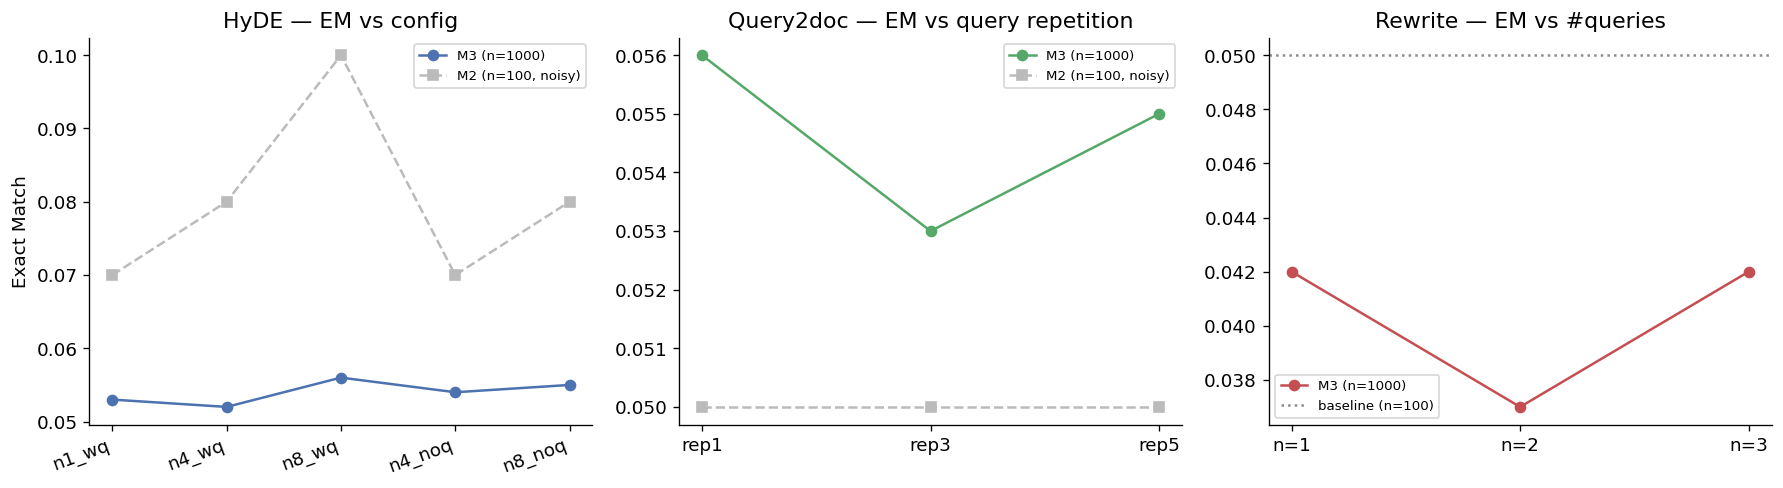

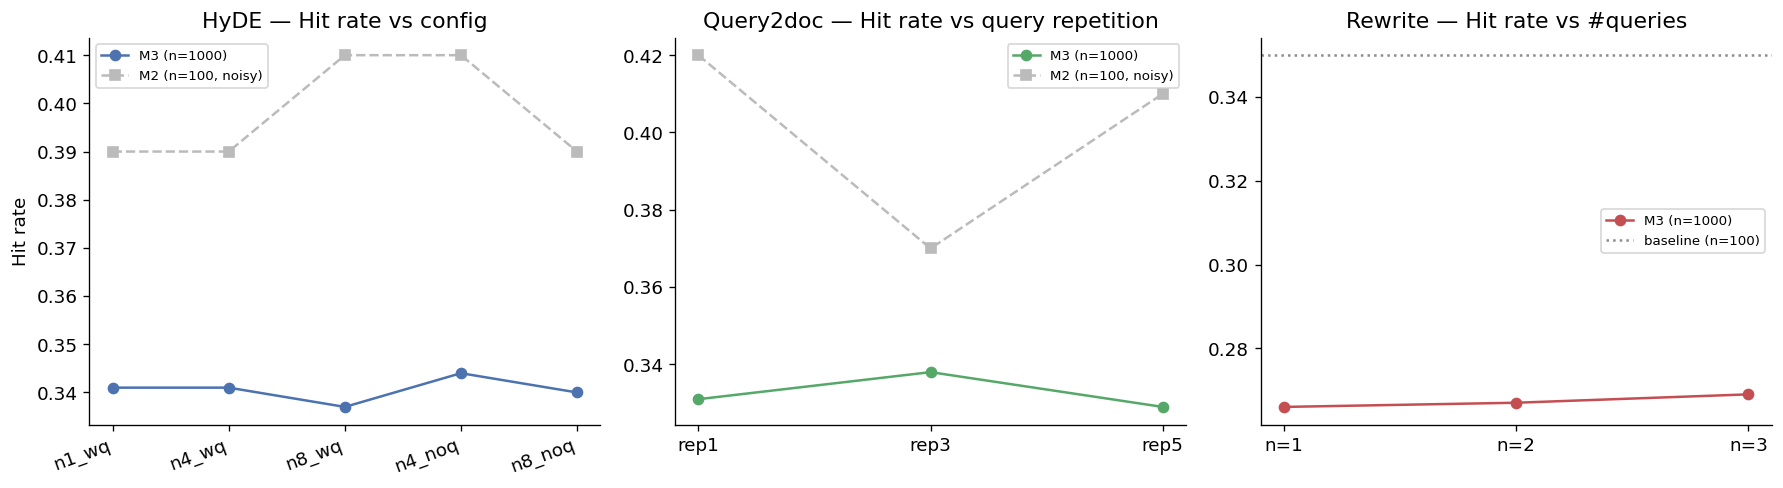

,"config (M3, n=1000)",EM,Hit,ROUGE-L,F1
0,hyde_n1_wq,0.053,0.341,0.142,0.140
1,hyde_n4_wq,0.052,0.341,0.137,0.134
2,hyde_n8_wq,0.056,0.337,0.142,0.138
3,hyde_n4_noq,0.054,0.344,0.141,0.138
4,hyde_n8_noq,0.055,0.340,0.140,0.138
5,query2doc_rep1,0.056,0.331,0.133,0.131
6,query2doc_rep3,0.053,0.338,0.134,0.130
7,query2doc_rep5,0.055,0.329,0.136,0.133
8,rewrite_n1,0.042,0.266,0.122,0.120
9,rewrite_n2,0.037,0.267,0.116,0.114


In [13]:
def get_em_hit(metrics):
    return metrics["exact_match"], metrics["retrieval_hit_rate"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# ---- HyDE ----
hyde_cfgs = ["hyde_n1_wq", "hyde_n4_wq", "hyde_n8_wq", "hyde_n4_noq", "hyde_n8_noq"]
xt = [c.replace("hyde_", "") for c in hyde_cfgs]
x = np.arange(len(hyde_cfgs))
em3 = [ABL_M3[c]["exact_match"] for c in hyde_cfgs]
em2 = [ABL_M2[c]["exact_match"] if ABL_M2.get(c) else np.nan for c in hyde_cfgs]
axes[0].plot(x, em3, "o-", color=COLORS["best_hyde"], label="M3 (n=1000)")
axes[0].plot(x, em2, "s--", color="#bbbbbb", label="M2 (n=100, noisy)")
axes[0].set_xticks(x); axes[0].set_xticklabels(xt, rotation=20, ha="right")
axes[0].set_title("HyDE — EM vs config"); axes[0].set_ylabel("Exact Match"); axes[0].legend(fontsize=8)

# ---- Query2doc ----
q2d_cfgs = ["query2doc_rep1", "query2doc_rep3", "query2doc_rep5"]
xt = ["rep1", "rep3", "rep5"]; x = np.arange(len(q2d_cfgs))
em3 = [ABL_M3[c]["exact_match"] for c in q2d_cfgs]
em2 = [ABL_M2[c]["exact_match"] if ABL_M2.get(c) else np.nan for c in q2d_cfgs]
axes[1].plot(x, em3, "o-", color=COLORS["best_query2doc"], label="M3 (n=1000)")
axes[1].plot(x, em2, "s--", color="#bbbbbb", label="M2 (n=100, noisy)")
axes[1].set_xticks(x); axes[1].set_xticklabels(xt)
axes[1].set_title("Query2doc — EM vs query repetition"); axes[1].legend(fontsize=8)

# ---- Rewrite ----
rw_cfgs = ["rewrite_n1", "rewrite_n2", "rewrite_n3"]
xt = ["n=1", "n=2", "n=3"]; x = np.arange(len(rw_cfgs))
em3 = [ABL_M3[c]["exact_match"] for c in rw_cfgs]
axes[2].plot(x, em3, "o-", color=COLORS["best_rewrite"], label="M3 (n=1000)")
axes[2].axhline(SHARED_BASELINE["exact_match"], color="#8C8C8C", ls=":", label="baseline (n=100)")
axes[2].set_xticks(x); axes[2].set_xticklabels(xt)
axes[2].set_title("Rewrite — EM vs #queries"); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# ---- HyDE ----
hyde_cfgs = ["hyde_n1_wq", "hyde_n4_wq", "hyde_n8_wq", "hyde_n4_noq", "hyde_n8_noq"]
xt = [c.replace("hyde_", "") for c in hyde_cfgs]
x = np.arange(len(hyde_cfgs))
em3 = [ABL_M3[c]["retrieval_hit_rate"] for c in hyde_cfgs]
em2 = [ABL_M2[c]["retrieval_hit_rate"] if ABL_M2.get(c) else np.nan for c in hyde_cfgs]
axes[0].plot(x, em3, "o-", color=COLORS["best_hyde"], label="M3 (n=1000)")
axes[0].plot(x, em2, "s--", color="#bbbbbb", label="M2 (n=100, noisy)")
axes[0].set_xticks(x); axes[0].set_xticklabels(xt, rotation=20, ha="right")
axes[0].set_title("HyDE — Hit rate vs config"); axes[0].set_ylabel("Hit rate"); axes[0].legend(fontsize=8)

# ---- Query2doc ----
q2d_cfgs = ["query2doc_rep1", "query2doc_rep3", "query2doc_rep5"]
xt = ["rep1", "rep3", "rep5"]; x = np.arange(len(q2d_cfgs))
em3 = [ABL_M3[c]["retrieval_hit_rate"] for c in q2d_cfgs]
em2 = [ABL_M2[c]["retrieval_hit_rate"] if ABL_M2.get(c) else np.nan for c in q2d_cfgs]
axes[1].plot(x, em3, "o-", color=COLORS["best_query2doc"], label="M3 (n=1000)")
axes[1].plot(x, em2, "s--", color="#bbbbbb", label="M2 (n=100, noisy)")
axes[1].set_xticks(x); axes[1].set_xticklabels(xt)
axes[1].set_title("Query2doc — Hit rate vs query repetition"); axes[1].legend(fontsize=8)

# ---- Rewrite ----
rw_cfgs = ["rewrite_n1", "rewrite_n2", "rewrite_n3"]
xt = ["n=1", "n=2", "n=3"]; x = np.arange(len(rw_cfgs))
em3 = [ABL_M3[c]["retrieval_hit_rate"] for c in rw_cfgs]
axes[2].plot(x, em3, "o-", color=COLORS["best_rewrite"], label="M3 (n=1000)")
axes[2].axhline(SHARED_BASELINE["retrieval_hit_rate"], color="#8C8C8C", ls=":", label="baseline (n=100)")
axes[2].set_xticks(x); axes[2].set_xticklabels(xt)
axes[2].set_title("Rewrite — Hit rate vs #queries"); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

# Print the M3 ablation table
rows = []
for c in ABL_LABELS:
    m = ABL_M3[c]
    rows.append((c, m["exact_match"], m["retrieval_hit_rate"], m["rouge_l"], m["token_f1"]))
display(pd.DataFrame(rows, columns=["config (M3, n=1000)", "EM", "Hit", "ROUGE-L", "F1"]).round(3))


**Reading it.**

- **HyDE**: all five configs land in EM 0.052–0.056, Hit 0.337–0.344 ; a ~0.4 pp spread, well
  within noise even at n=1000. The M2 swings (0.06→0.10) have collapsed. We have *candidates*,
  not a *winner*: `hyde_n8_wq` (best EM) and `hyde_n4_noq` (best Hit) are indistinguishable here.
- **Query2doc**: `rep ∈ {1,3,5}` is flat (EM 0.053–0.056). This empirically confirms Wang et al. paper:
  query repetition matters for **sparse** BM25 but is inert for a **dense** encoder like
  contriever. `rep1` is the paper-faithful dense default.
- **Rewrite**: every config sits *below* baseline on Hit (0.27 vs 0.35 baseline-at-n100 / 0.34
  for the transform methods) and EM never exceeds baseline. Multi-query does **not** rescue it.

Because the HyDE and Q2D candidates are tied, a single-seed ablation cannot choose. → Stage 2.

---
## 5 · Stage 2 — multi-seed tiebreak on N=1000 (3 seeds)

To choose between statistically tied candidates we move from points to **distributions**: run
the top-2 HyDE and top-2 Query2doc configs with 3 seeds and compare with error bars. (Methods
are stochastic because they sample at T>0; the reader is greedy.)


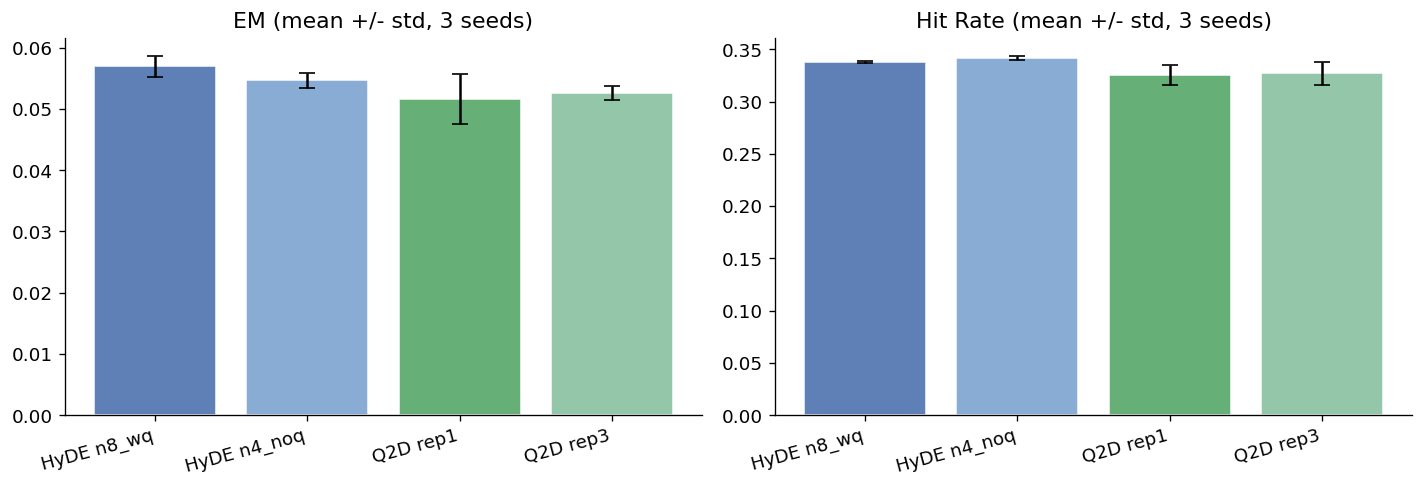

,config,EM (mean±std),Hit (mean±std)
0,HyDE n8_wq,0.0570 ± 0.0017,0.3380 ± 0.0010
1,HyDE n4_noq,0.0547 ± 0.0012,0.3420 ± 0.0020
2,Q2D rep1,0.0517 ± 0.0040,0.3253 ± 0.0096
3,Q2D rep3,0.0527 ± 0.0012,0.3270 ± 0.0111


In [14]:
tb = TIEBREAK["summary"]
order = ["hyde_n8_wq_1000qavgtest", "hyde_n4_noq_1000qavgtest",
         "query2doc_rep1_1000qavgtest", "query2doc_rep3_1000qavgtest"]
nice  = {"hyde_n8_wq_1000qavgtest": "HyDE n8_wq",
         "hyde_n4_noq_1000qavgtest": "HyDE n4_noq",
         "query2doc_rep1_1000qavgtest": "Q2D rep1",
         "query2doc_rep3_1000qavgtest": "Q2D rep3"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, title in [(axes[0], "exact_match", "EM (mean +/- std, 3 seeds)"),
                          (axes[1], "retrieval_hit_rate", "Hit Rate (mean +/- std, 3 seeds)")]:
    means = [tb[k]["aggregated_metrics"][metric]["mean"] for k in order]
    stds  = [tb[k]["aggregated_metrics"][metric]["std"]  for k in order]
    cols  = ["#4C72B0", "#7BA3D0", "#55A868", "#88C0A0"]
    ax.bar(range(len(order)), means, yerr=stds, capsize=5, color=cols, alpha=0.9, edgecolor="white")
    ax.set_xticks(range(len(order))); ax.set_xticklabels([nice[k] for k in order], rotation=15, ha="right")
    ax.set_title(title)
plt.tight_layout(); plt.show()

rows = []
for k in order:
    am = tb[k]["aggregated_metrics"]
    rows.append((nice[k],
                 f"{am['exact_match']['mean']:.4f} ± {am['exact_match']['std']:.4f}",
                 f"{am['retrieval_hit_rate']['mean']:.4f} ± {am['retrieval_hit_rate']['std']:.4f}"))
display(pd.DataFrame(rows, columns=["config", "EM (mean±std)", "Hit (mean±std)"]))


**Decision.**

- **HyDE**: `n8_wq` has the higher mean EM (0.057 vs 0.055) with tight seed-to-seed spread, while
  `n4_noq` edges Hit (0.342 vs 0.338). EM is the headline QA metric, and `n8_wq` is also what corresponds best to the paper-canonical Eq. 8 (averaging + query anchor). → **`hyde_n8_wq`**.
- **Query2doc**: `rep1` and `rep3` overlap on every metric (their error bars cross). → **`rep1`**,
  the paper-faithful dense default — no reason to add query repetition that the encoder ignores.
- **Rewrite**: never competitive in Stage 1; carried forward as **`n_queries=3`** (the most
  canonical Ma et al. variant) so the held-out test reports the *strongest* rewrite, not a
  strawman.

---
## 6 · Stage 3 — held-out test (N=2610, indices 1000–3609, 3 seeds)

The selected config per method, evaluated on a slice **never used for tuning**. Stochastic
methods report mean ± std over 3 seeds; baseline is deterministic.


In [15]:
def agg(label, metric):
    a = STATS["test"][label]["metrics_agg"][metric]
    return a["mean"], a["std"]

metric_keys = [("em", "EM"), ("hit", "Hit Rate"), ("rouge_l", "ROUGE-L"), ("f1", "Token F1")]
rows = []
for m in METHODS:
    row = {"Method": LABELS[m]}
    for key, name in metric_keys:
        mean, std = agg(m, key)
        row[name] = f"{mean:.4f} ± {std:.4f}" if std > 0 else f"{mean:.4f}"
    rows.append(row)
headline = pd.DataFrame(rows).set_index("Method")
print("Held-out test, N=2610, 3 seeds:")
display(headline)

# Delta vs baseline (percentage points)
base_em, _  = agg("best_baseline", "em")
base_hit, _ = agg("best_baseline", "hit")
print("\nDelta vs baseline (pp):")
for m in METHODS[1:]:
    de = (agg(m, "em")[0]  - base_em)  * 100
    dh = (agg(m, "hit")[0] - base_hit) * 100
    print(f"  {LABELS[m]:<10} dEM = {de:+.2f} pp   dHit = {dh:+.2f} pp")


Held-out test, N=2610, 3 seeds:


,EM,Hit Rate,ROUGE-L,Token F1
Method,,,,
Baseline,0.0341,0.2690,0.1093,0.1037
HyDE,0.0460 ± 0.0014,0.3236 ± 0.0015,0.1288 ± 0.0008,0.1238 ± 0.0007
Query2doc,0.0469 ± 0.0015,0.3096 ± 0.0037,0.1290 ± 0.0011,0.1242 ± 0.0011
Rewrite,0.0346 ± 0.0010,0.2538 ± 0.0020,0.1090 ± 0.0009,0.1051 ± 0.0008



Delta vs baseline (pp):
  HyDE       dEM = +1.19 pp   dHit = +5.47 pp
  Query2doc  dEM = +1.28 pp   dHit = +4.06 pp
  Rewrite    dEM = +0.05 pp   dHit = -1.52 pp


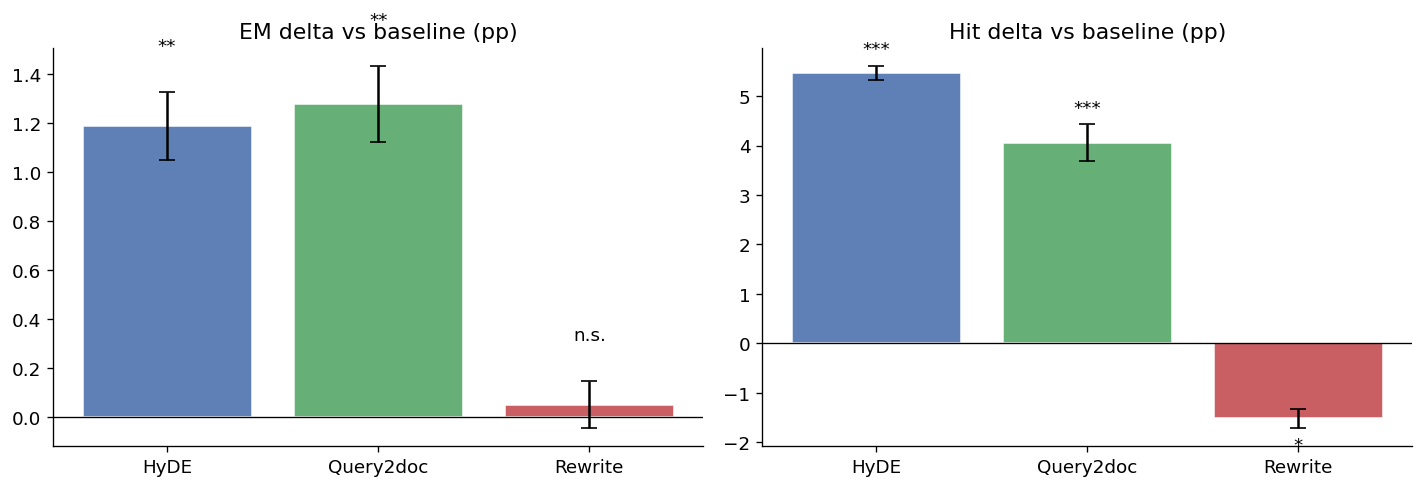

Significance from McNemar (worst of 3 seeds): *** p<0.001, ** p<0.01, * p<0.05, n.s. = not significant


In [16]:
# Delta bar chart with multi-seed error bars + significance stars from McNemar.
paired = STATS["paired_vs_baseline"]
methods = ["best_hyde", "best_query2doc", "best_rewrite"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, dkey, pkey, title in [
        (axes[0], "em_diff_pp",  "em_mcnemar_pvalue_max",  "EM delta vs baseline (pp)"),
        (axes[1], "hit_diff_pp", "hit_mcnemar_pvalue_max", "Hit delta vs baseline (pp)")]:
    means = [paired[m]["summary"][f"{dkey}_mean"] for m in methods]
    stds  = [paired[m]["summary"][f"{dkey}_std"]  for m in methods]
    cols  = [COLORS[m] for m in methods]
    bars  = ax.bar(range(len(methods)), means, yerr=stds, capsize=5, color=cols,
                   alpha=0.9, edgecolor="white")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(len(methods))); ax.set_xticklabels([LABELS[m] for m in methods])
    ax.set_title(title)
    for i, m in enumerate(methods):
        pv = paired[m]["summary"][pkey]
        star = "***" if pv < 0.001 else "**" if pv < 0.01 else "*" if pv < 0.05 else "n.s."
        y = means[i] + (stds[i] + 0.15) * (1 if means[i] >= 0 else -1)
        ax.text(i, y, star, ha="center", va="bottom" if means[i] >= 0 else "top", fontsize=11)
plt.tight_layout(); plt.show()
print("Significance from McNemar (worst of 3 seeds): *** p<0.001, ** p<0.01, * p<0.05, n.s. = not significant")


**Headline finding.** On the held-out split, **HyDE and Query2doc both significantly beat
baseline**: ≈ **+1.2 EM** and **+4–5.5 Hit** (percentage points), with very small seed-to-seed
std. **Rewrite is null-to-negative**: EM unchanged, Hit *down* ~1.5 pp. The honest M3 effects
(~+1.2 EM) are much smaller than the M2 "+3–5 EM"; exactly the winner's curse correction we set
out to make, but they are now statistically real.

---
## 7 · Statistical significance

EM and Hit are **paired binary** outcomes (same question, two systems), so the right test is
**McNemar's exact test** on the discordant pairs, not a t-test. This test looks only at the questions where the two systems *disagree*; *recoveries* (baseline wrong → method right) versus *regressions* (baseline right → method wrong). HyDE and Query2doc post far more recoveries than regressions on both EM and Hit (p < 0.01 → `**`/`***`), so their gains are *real, not sampling noise*. Rewrite's EM is a near-perfect tie (≈ 27 vs 26 flips → p ≈ 1, `n.s.`: indistinguishable from baseline), while its Hit shows significantly *more* regressions (`*`, but the bar points down).

For the continuous metrics
(F1, ROUGE-L) I use a **paired t-test**. All on N=2610. The summary p-value per method is the
**worst across the 3 seeds** (conservative: if even the unluckiest seed is significant, the
effect is solid).


In [17]:
rows = []
for m in ["best_hyde", "best_query2doc", "best_rewrite"]:
    s = paired[m]["summary"]
    s0 = paired[m]["per_seed"]["seed_0"]
    rows.append({
        "Method": LABELS[m],
        "dEM (pp)":  f"{s['em_diff_pp_mean']:+.2f}",
        "EM McNemar p (max)":  f"{s['em_mcnemar_pvalue_max']:.2e}",
        "dHit (pp)": f"{s['hit_diff_pp_mean']:+.2f}",
        "Hit McNemar p (max)": f"{s['hit_mcnemar_pvalue_max']:.2e}",
        "F1 paired-t p (seed0)":  f"{s0['f1_paired_t']['p_value']:.2e}",
        "ROUGE-L paired-t p (seed0)": f"{s0['rouge_l_paired_t']['p_value']:.2e}",
    })
display(pd.DataFrame(rows).set_index("Method"))

# McNemar discordant counts for seed 0 (recoveries b vs regressions c)
print("\nMcNemar discordant pairs (seed 0):  b = baseline wrong -> method right (recoveries),"
      "  c = baseline right -> method wrong (regressions)")
for m in ["best_hyde", "best_query2doc", "best_rewrite"]:
    em = paired[m]["per_seed"]["seed_0"]["em_mcnemar"]
    hit = paired[m]["per_seed"]["seed_0"]["hit_mcnemar"]
    print(f"  {LABELS[m]:<10} EM: b={em['b']:>3} c={em['c']:>3}   |   Hit: b={hit['b']:>3} c={hit['c']:>3}")


,dEM (pp),EM McNemar p (max),dHit (pp),Hit McNemar p (max),F1 paired-t p (seed0),ROUGE-L paired-t p (seed0)
Method,,,,,,
HyDE,+1.19,2.03e-03,+5.47,0.00e+00,1.06e-08,3.88e-08
Query2doc,+1.28,1.93e-03,+4.06,0.00e+00,1.77e-07,3.33e-07
Rewrite,+0.05,1.00e+00,-1.52,1.64e-02,7.16e-01,9.64e-01



McNemar discordant pairs (seed 0):  b = baseline wrong -> method right (recoveries),  c = baseline right -> method wrong (regressions)
  HyDE       EM: b= 56 c= 21   |   Hit: b=204 c= 64
  Query2doc  EM: b= 61 c= 27   |   Hit: b=185 c= 85
  Rewrite    EM: b= 27 c= 26   |   Hit: b= 74 c=115


### Effect sizes with uncertainty — paired bootstrap

McNemar does not tell us how big the effect is. For that we put a **confidence interval around each delta** with a **paired bootstrap**:

1. Resample the **2610 question indices** with replacement (5000 times). Crucially we resample
   *indices*, not the two systems independently — so baseline and method are always scored on the
   *same* resampled questions, preserving the within-question pairing.
2. For each resample, recompute the metric for both systems and take the **delta** (method − baseline).
3. The 2.5th and 97.5th percentiles of those 5000 deltas give a **95 % confidence interval**.

**Reading the forest plot.** Each bar is a 95 % CI; the red dashed line is zero (no effect).
A CI **entirely above zero** = a significant improvement; **straddling zero** = indistinguishable
from baseline; **entirely below zero** = a significant degradation. This is the visual companion to
the McNemar p-values: HyDE and Query2doc sit clearly to the right on both EM and Hit, Rewrite's EM
spans zero, and Rewrite's Hit sits entirely to the left.

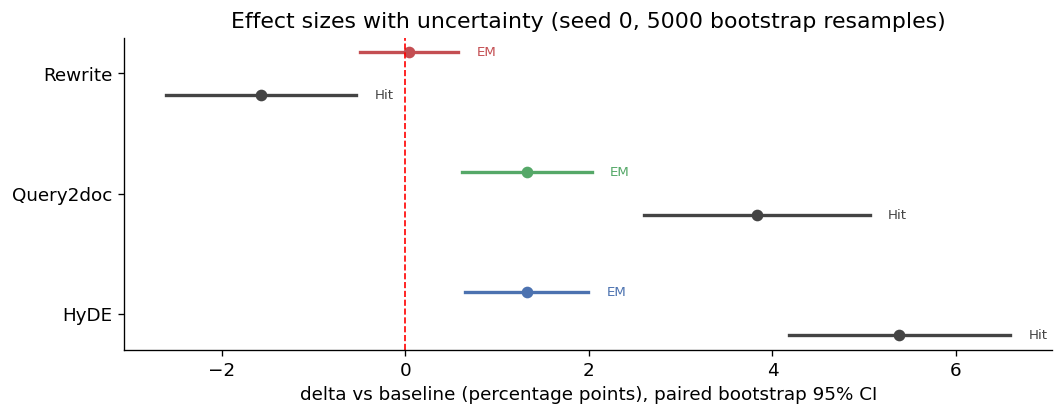

In [19]:
# Forest plot: paired bootstrap 95% CI for the EM and Hit deltas (seed 0).
fig, ax = plt.subplots(figsize=(9, 3.6))
methods = ["best_hyde", "best_query2doc", "best_rewrite"]
yticks, ylabels = [], []
y = 0
for m in methods:
    s0 = paired[m]["per_seed"]["seed_0"]
    for metric, off, mk in [("em_diff_ci_95", 0.18, "EM"), ("hit_diff_ci_95", -0.18, "Hit")]:
        lo, hi = [v * 100 for v in s0[metric]]
        mid = (lo + hi) / 2
        col = COLORS[m] if mk == "EM" else "#444444"
        ax.plot([lo, hi], [y + off]*2, color=col, lw=2)
        ax.plot(mid, y + off, "o", color=col)
        ax.text(hi + 0.2, y + off, mk, va="center", fontsize=8, color=col)
    yticks.append(y); ylabels.append(LABELS[m]); y += 1
ax.axvline(0, color="red", ls="--", lw=1)
ax.set_yticks(yticks); ax.set_yticklabels(ylabels)
ax.set_xlabel("delta vs baseline (percentage points), paired bootstrap 95% CI")
ax.set_title("Effect sizes with uncertainty (seed 0, 5000 bootstrap resamples)")
plt.tight_layout(); plt.show()


**Reading it.**

- **HyDE & Query2doc**: EM McNemar p ≈ 2×10⁻³ (worst seed), Hit p ≈ 10⁻⁹ to 10⁻¹⁸; F1/ROUGE
  paired-t p ≈ 10⁻⁷–10⁻⁸. The EM and Hit CIs sit **entirely above zero**. Real effects.
- **Rewrite**: EM McNemar p = 1.0 (b≈c — as many recoveries as regressions), the EM CI straddles
  zero, and the Hit CI is **entirely below zero** (significantly *worse* retrieval). Rewrite
  measurably hurts retrieval without helping answers.


---
## 8 · Where does the gain come from? Retrieval vs generation (EM | Hit)

Aggregate EM conflates two failures: the answer isn't retrieved (retrieval miss), or it is
retrieved but the reader doesn't extract it (generation miss). **EM | Hit** ; EM restricted to
questions whose gold answer appears in the chunks, isolates the generation side. A method can
raise EM by raising Hit, by raising EM|Hit, or both.


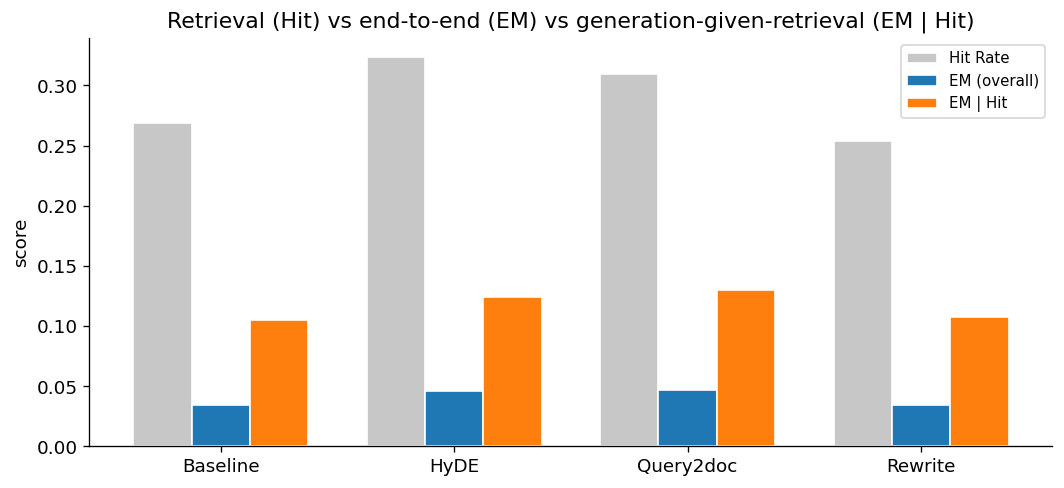

,Hit,EM,EM|Hit,EM|Miss,n_hits (mean)
Method,,,,,
Baseline,0.2690,0.0341,0.1054,0.0079,702.0
HyDE,0.3236,0.0460,0.1243,0.0085,845.0
Query2doc,0.3096,0.0469,0.1300,0.0096,808.0
Rewrite,0.2538,0.0346,0.1077,0.0098,662.0


In [22]:
eh = STATS["em_given_hit"]
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(METHODS)); w = 0.25

em_vals  = [agg(m, "em")[0]  for m in METHODS]
hit_vals = [agg(m, "hit")[0] for m in METHODS]
emh_vals = [eh[m]["em_given_hit_mean"] for m in METHODS]

# One colour PER METRIC so the legend matches the bars
# (the four methods are identified by the x-axis labels, not by colour here).
C_HIT, C_EM, C_EMH = "#c7c7c7", "#1f77b4", "#ff7f0e"
ax.bar(x - w, hit_vals, w, label="Hit Rate",    color=C_HIT, edgecolor="white")
ax.bar(x,     em_vals,  w, label="EM (overall)", color=C_EM,  edgecolor="white")
ax.bar(x + w, emh_vals, w, label="EM | Hit",     color=C_EMH, edgecolor="white")

ax.set_xticks(x); ax.set_xticklabels([LABELS[m] for m in METHODS])
ax.set_ylabel("score")
ax.set_title("Retrieval (Hit) vs end-to-end (EM) vs generation-given-retrieval (EM | Hit)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

rows = []
for m in METHODS:
    rows.append({"Method": LABELS[m],
                 "Hit": round(agg(m, "hit")[0], 4),
                 "EM": round(agg(m, "em")[0], 4),
                 "EM|Hit": round(eh[m]["em_given_hit_mean"], 4),
                 "EM|Miss": round(eh[m]["em_given_miss_mean"], 4),
                 "n_hits (mean)": round(eh[m]["n_hits_mean"], 0)})
display(pd.DataFrame(rows).set_index("Method"))

**Reading it.** Decomposing the EM gain via
EM = Hit·(EM|Hit) + (1−Hit)·(EM|Miss) shows that HyDE and Query2doc have opposite profiles:
**HyDE's** +1.2 EM splits almost evenly between retrieval and extraction (≈ +0.53 pp from Hit
0.269→0.324, +143 more questions with the answer in context; ≈ +0.51 pp from EM|Hit 0.105→0.124).
**Query2doc's** gain comes *mostly from extraction*: it has the highest EM|Hit of all methods
(0.105→0.130, ≈ +0.66 pp) on top of a smaller retrieval gain (Hit +4 pp, ≈ +0.40 pp); consistent
with Q2D keeping the original question verbatim alongside the pseudo-doc, which helps the reader
extract. **EM|Miss** stays ~0.008–0.010 across all methods: closed-book guessing is unaffected by
the query stage (a clean placebo check; the small drift only reflects that each method misses a
slightly different subset). **Rewrite** barely moves EM|Hit and loses Hit, so it has nothing to
convert.

---
## 9 · Bias diagnostic — *real* mitigation vs *apparent* mitigation

A metric gain can hide two very different mechanisms: the retriever
became genuinely more semantic (**decorrelation**), or it just swapped one surface bias for
another (**redistribution**). We measure the Spearman ρ between the top-1 retrieval score and
four surface features of the retrieved chunk: brevity, literal (Jaccard) overlap with the query,
answer position, and query-term repetition. ρ≈0 = the score ignores that surface feature
(desirable).

*(Rewrite multi-query is excluded: its retrieval is done inside the transform and stores no
per-chunk score, so ρ is undefined by construction.)*


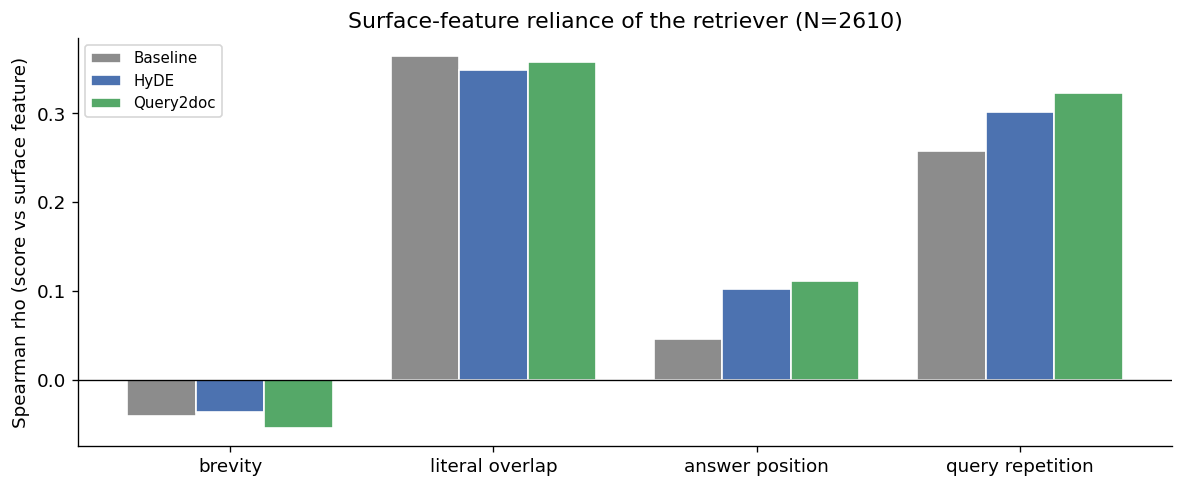

,brevity,literal overlap,answer position,query repetition
config,,,,
Baseline,-0.041,0.364,0.046,0.258
HyDE,-0.036,0.348,0.102,0.302
Query2doc,-0.054,0.358,0.111,0.322


In [23]:
bias = STATS["bias_diagnostic"]
feat = ["brevity_rho", "literal_rho", "position_rho", "repetition_rho"]
feat_lbl = ["brevity", "literal overlap", "answer position", "query repetition"]
keys = [("best_baseline", "Baseline", "#8C8C8C"),
        ("best_hyde_seed0", "HyDE", "#4C72B0"),
        ("best_query2doc_seed0", "Query2doc", "#55A868")]

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(feat)); w = 0.26
for i, (k, lbl, col) in enumerate(keys):
    vals = [bias[k][f] for f in feat]
    ax.bar(x + (i - 1) * w, vals, w, label=lbl, color=col, edgecolor="white")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(feat_lbl)
ax.set_ylabel("Spearman rho (score vs surface feature)")
ax.set_title("Surface-feature reliance of the retriever (N=2610)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

rows = [{"config": lbl, **{fl: round(bias[k][f], 3) for f, fl in zip(feat, feat_lbl)}}
        for k, lbl, col in keys]
display(pd.DataFrame(rows).set_index("config"))


**Reading it — this is the most interesting diagnostic.** Literal-overlap reliance stays
essentially constant (ρ ≈ 0.36 baseline → 0.35 HyDE/Q2D): the retriever is **not** becoming more
semantic. Instead, **answer-position** reliance roughly doubles (0.046 → 0.10–0.11) and
**query-repetition** reliance rises (0.26 → 0.30–0.32). HyDE and Query2doc improve Hit not by
removing surface bias but by **redistributing** it: apparent (variance-based)
rather than real (decorrelation-based) mitigation. The mechanism is
visible in the next section: the pseudo-docs are long and term-rich, so the retriever has
*more* surface signal to exploit, just along different axes.


---
## 10 · Performance breakdown by question type

NQ Open questions have predictable surface forms. Do the gains concentrate on particular types?


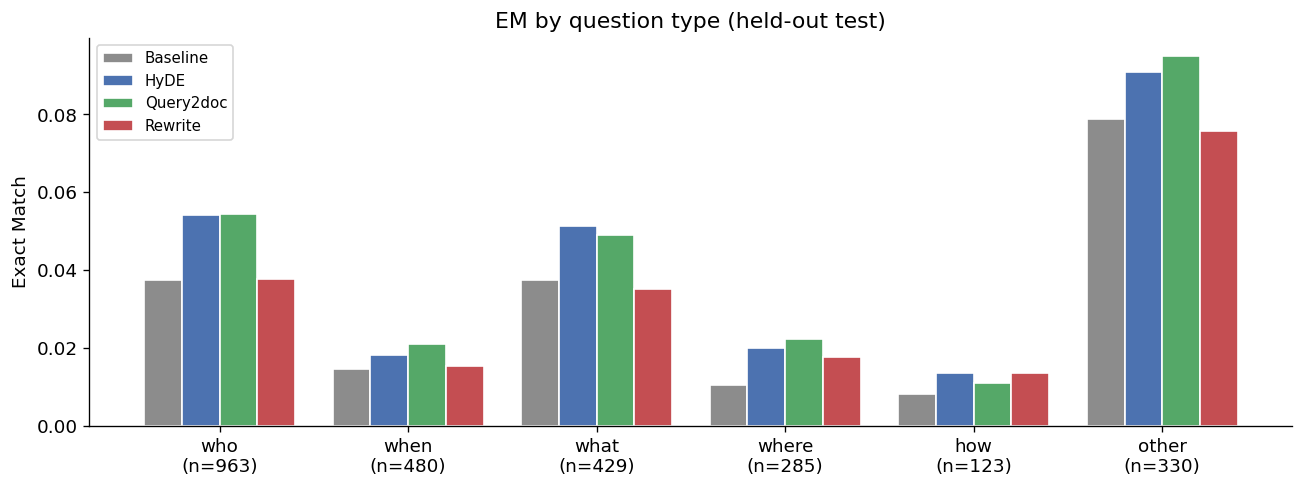

,n,Baseline,HyDE,Query2doc,Rewrite
type,,,,,
who,963,0.037,0.054,0.054,0.038
when,480,0.015,0.018,0.021,0.015
what,429,0.037,0.051,0.049,0.035
where,285,0.011,0.020,0.022,0.018
how,123,0.008,0.014,0.011,0.014
other,330,0.079,0.091,0.095,0.076


In [24]:
qt = STATS["qtype_breakdown"]
counts = qt["__counts__"]
types = ["who", "when", "what", "where", "how", "other"]

def qt_em(label, t):
    d = qt[label][t]
    return d["em"] if "em" in d else d["em_mean"]

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(types)); w = 0.2
for i, m in enumerate(METHODS):
    vals = [qt_em(m, t) for t in types]
    ax.bar(x + (i - 1.5) * w, vals, w, label=LABELS[m], color=COLORS[m], edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels([f"{t}\n(n={counts[t]})" for t in types])
ax.set_ylabel("Exact Match"); ax.set_title("EM by question type (held-out test)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

rows = []
for t in types:
    row = {"type": t, "n": counts[t]}
    for m in METHODS:
        row[LABELS[m]] = round(qt_em(m, t), 3)
    rows.append(row)
display(pd.DataFrame(rows).set_index("type"))


**Reading it.** The gains are not uniform. `who` questions (n=963, the largest bucket)
improve most under HyDE/Q2D (EM 0.037 → ~0.054, roughly +45 % relative) — a hypothetical
biography supplies the surrounding named-entity context that a bare name-query lacks. `other`
(open-ended) questions are already the strongest bucket and stay flat. `when`/`where`/`how`
stay low everywhere: short factoids where the bottleneck is reader extraction, not retrieval.
**Rewrite hovers around baseline in every bucket**; the small ups and downs (e.g. `where`
0.011→0.018, `what` 0.037→0.035) are within noise; no question type it systematically helps,
consistent with its null overall EM.

---
## 11 · Abstention analysis — does better retrieval stop the reader refusing?

Mistral often refuses ("the context does not provide…") when it sees no clear signal. I split
abstentions into **false** (gold answer *was* in the chunks → a pure generation failure) and
**justified** (retrieval missed → correct RAG behaviour).


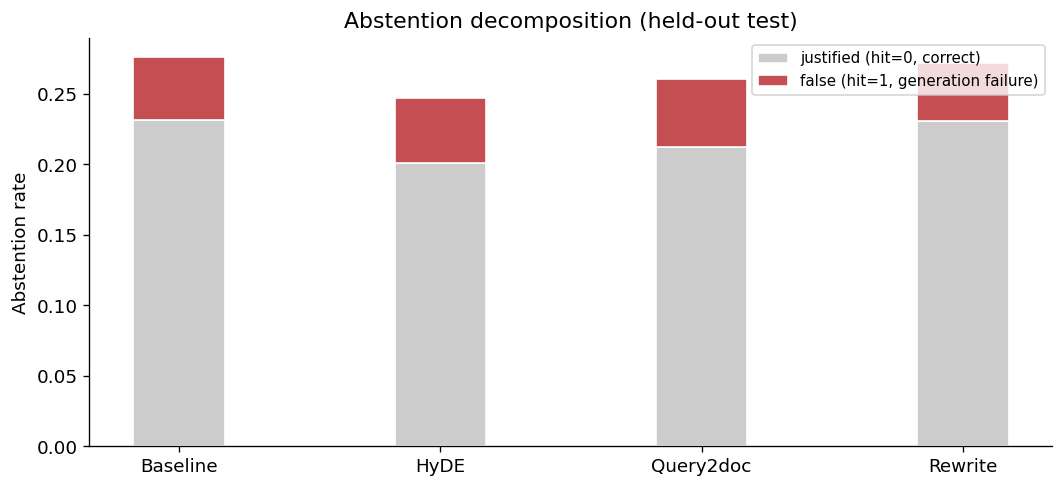

,total,false (hit=1),justified (hit=0)
Method,,,
Baseline,0.2759,0.0448,0.2310
HyDE,0.2467,0.0458,0.2009
Query2doc,0.2604,0.0480,0.2124
Rewrite,0.2718,0.0415,0.2303


In [25]:
ab = STATS["abstention"]
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(METHODS)); w = 0.35
false_r = [ab[m]["false_abstention_rate"]["mean"] for m in METHODS]
just_r  = [ab[m]["just_abstention_rate"]["mean"]  for m in METHODS]
ax.bar(x, just_r, w, label="justified (hit=0, correct)", color="#cccccc", edgecolor="white")
ax.bar(x, false_r, w, bottom=just_r, label="false (hit=1, generation failure)",
       color="#C44E52", edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([LABELS[m] for m in METHODS])
ax.set_ylabel("Abstention rate"); ax.set_title("Abstention decomposition (held-out test)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

rows = []
for m in METHODS:
    rows.append({"Method": LABELS[m],
                 "total": round(ab[m]["abstention_rate"]["mean"], 4),
                 "false (hit=1)": round(ab[m]["false_abstention_rate"]["mean"], 4),
                 "justified (hit=0)": round(ab[m]["just_abstention_rate"]["mean"], 4)})
display(pd.DataFrame(rows).set_index("Method"))


**Reading it: a clean mechanistic result.** HyDE cuts *total* abstention 0.276 → 0.247,
but the **false-abstention rate is unchanged** (0.045 → 0.046). The entire reduction comes from
**justified** abstentions (0.231 → 0.201): HyDE retrieves on-topic chunks for questions where
the baseline retrieved nothing usable, so the reader stops (correctly) saying "no information".
It does not help the reader extract from chunks it already had. This dovetails with:
HyDE's lever is *retrieval*, not *extraction*.


---
## 12 · What the retriever actually sees: pseudo-doc / rewrite lengths

This contextualises the bias diagnostic : how much extra text each method injects into the
query stage.


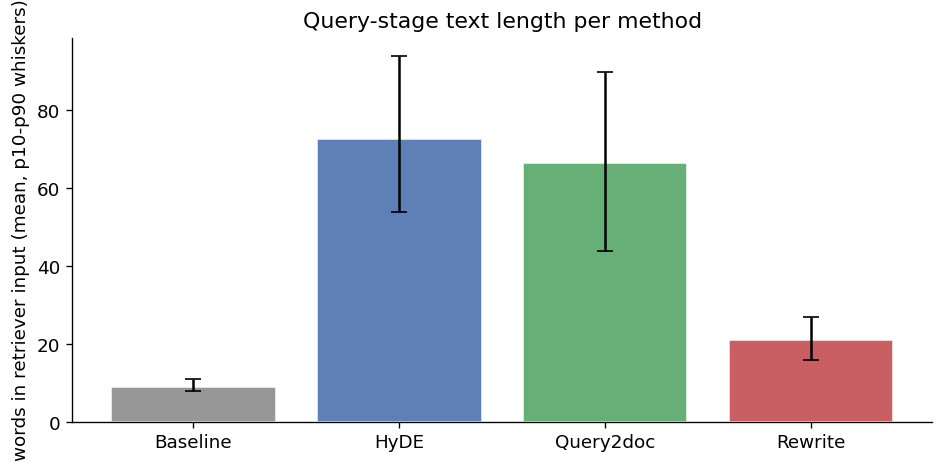

,mean words,median,p10,p90
Method,,,,
Baseline,9.2,9.0,8.0,11.0
HyDE,72.6,71.0,54.0,94.0
Query2doc,66.4,66.0,44.0,90.0
Rewrite,21.0,20.0,16.0,27.0


In [26]:
il = STATS["intermediate_lengths"]
order = ["best_baseline", "best_hyde", "best_query2doc", "best_rewrite"]
means = [il[m]["mean_words"] for m in order]
p10   = [il[m]["mean_words"] - il[m]["p10_words"] for m in order]
p90   = [il[m]["p90_words"] - il[m]["mean_words"] for m in order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(order)), means, yerr=[p10, p90], capsize=5,
       color=[COLORS[m] for m in order], alpha=0.9, edgecolor="white")
ax.set_xticks(range(len(order))); ax.set_xticklabels([LABELS[m] for m in order])
ax.set_ylabel("words in retriever input (mean, p10-p90 whiskers)")
ax.set_title("Query-stage text length per method")
plt.tight_layout(); plt.show()

rows = [{"Method": LABELS[m], "mean words": round(il[m]["mean_words"], 1),
         "median": il[m]["median_words"], "p10": il[m]["p10_words"], "p90": il[m]["p90_words"]}
        for m in order]
display(pd.DataFrame(rows).set_index("Method"))


**Reading it.** The bare question is ~9 words; HyDE balloons it to ~73, Query2doc to ~66,
Rewrite *shrinks* it to ~21 (it canonicalises, dropping function words). HyDE
and Q2D give the retriever a long, term-rich passage, so the score has *more* surface features
to latch onto (position, repetition ρ rise). Rewrite does the opposite; it strips the query down
to keywords, pushing the retriever toward **literal lexical matching** and away from contriever's
semantic strength, which is precisely why its Hit rate drops.


---
## 13 · Qualitative case studies; and a caveat about EM

The stats above count EM flips. But **not every EM "recovery" is a retrieval win**; some are
just formatting: the baseline already said the right thing verbosely or with a trailing period,
and the transform happens to phrase it as the bare gold string. I first *quantify* how many
recoveries are genuine, then show real examples.


In [27]:
def norm(s):
    return s.strip().lower().rstrip(". ")

def is_format_artifact(case):
    """Baseline already 'contained' the gold (verbose-correct or trailing punctuation)."""
    bp = case["baseline_pred"].strip().lower()
    return any(norm(g) in bp for g in case["gold"])

print("Recovery breakdown (baseline EM=0 -> method EM=1), seed 0:\n")
print(f"{'Method':<12}{'total recov.':>13}{'genuine':>10}{'format artifact':>17}")
for m in ["best_hyde", "best_query2doc", "best_rewrite"]:
    recs = CASES[m]["recoveries"]
    art = sum(is_format_artifact(c) for c in recs)
    gen = len(recs) - art
    print(f"{LABELS[m]:<12}{CASES[m]['n_recoveries_total']:>13}{gen:>10}{art:>17}"
          f"   (of {len(recs)} stored)")
print("\nNote: 'total' counts all recoveries; genuine/artifact are over the stored top-K only.")


Recovery breakdown (baseline EM=0 -> method EM=1), seed 0:

Method       total recov.   genuine  format artifact
HyDE                   56        17                8   (of 25 stored)
Query2doc              61        18                7   (of 25 stored)
Rewrite                27        14               11   (of 25 stored)

Note: 'total' counts all recoveries; genuine/artifact are over the stored top-K only.


In [28]:
# Show genuine HyDE/Q2D recoveries (baseline wrong or abstaining -> method right).
def show_cases(method, kind, n=3, only_genuine=True):
    print("=" * 96)
    print(f"  {LABELS[method]} — {kind}")
    print("=" * 96)
    shown = 0
    for c in CASES[method][kind]:
        if kind == "recoveries" and only_genuine and is_format_artifact(c):
            continue
        print(f"Q: {c['question']}")
        print(f"   gold     : {c['gold']}")
        print(f"   baseline : {c['baseline_pred'][:90]!r}")
        print(f"   {LABELS[method]:<8} : {c['treated_pred'][:90]!r}")
        print()
        shown += 1
        if shown >= n:
            break

show_cases("best_hyde", "recoveries", n=3)
show_cases("best_query2doc", "recoveries", n=3)


  HyDE — recoveries
Q: which state is the richest state in nigeria
   gold     : ['Lagos State']
   baseline : 'unknown from the provided context which state in Nigeria is the richest'
   HyDE     : 'Lagos State'

Q: bosnia and herzegovina croatia macedonia and slovenia all used to be parts of
   gold     : ['Yugoslavia']
   baseline : 'The Austro-Hungarian monarchy'
   HyDE     : 'Yugoslavia'

Q: 5 cities with the highest population in europe
   gold     : ['London', 'Saint Petersburg', 'Berlin', 'Moscow', 'Istanbul']
   baseline : 'According to the context, the five cities with the highest population in Europe, based on '
   HyDE     : 'Berlin'

  Query2doc — recoveries
Q: who is the director of nightmare before christmas
   gold     : ['Henry Selick']
   baseline : 'The context does not provide the name of the director for The Nightmare Before Christmas.'
   Query2doc : 'Henry Selick'

Q: bosnia and herzegovina croatia macedonia and slovenia all used to be parts of
   gold     : ['Y

In [29]:
# And the regressions — where the transform breaks a previously correct answer.
show_cases("best_hyde", "regressions", n=2, only_genuine=False)
show_cases("best_rewrite", "regressions", n=2, only_genuine=False)


  HyDE — regressions
Q: who invented the first home video security system
   gold     : ['her husband Albert Brown', 'Marie Van Brittan Brown']
   baseline : 'Marie Van Brittan Brown'
   HyDE     : 'Marie Van Brittan Brown\n\n(Reference: Passage 1, 2, 4)'

Q: computer based models of real life situation are called
   gold     : ['Computer simulation', 'Computer simulations']
   baseline : 'Computer simulations'
   HyDE     : 'Computational modeling'

  Rewrite — regressions
Q: what does g stand for in baseball stats
   gold     : ['Games', 'Games played']
   baseline : 'Games'
   Rewrite  : 'In the context provided, "G" stands for "Games." It is a baseball statistic used to indica'

Q: who is the actor who plays king joffrey
   gold     : ['Jack Gleeson']
   baseline : 'Jack Gleeson'
   Rewrite  : 'Jack Gleeson (from context in Passage 2, but Joffrey is from Game of Thrones, not mentione'



**Reading it.**

- A meaningful share of raw EM "recoveries" are **format artifacts** (e.g. baseline
  *"Michael Schumacher and Lewis Hamilton … 91 wins each"* → HyDE *"Michael Schumacher"*): the
  baseline knew the answer; HyDE only tightened the form. This is a real caveat for reading EM
  deltas — and a reason §8's EM|Hit and §11's abstention analyses matter, since they don't
  reward mere reformatting.
- The **genuine** recoveries are retrieval wins: baseline abstains ("the context does not
  provide…") or answers a wrong entity, and HyDE/Q2D pull in a chunk that actually contains the
  answer (e.g. *director of Nightmare Before Christmas → "Henry Selick"*).
- **Regressions** show the failure mode of injecting generated text: a confident but wrong
  pseudo-doc can steer retrieval toward a plausible-but-incorrect entity. For HyDE this is rare
  (b≫c, §7); for Rewrite it is as common as the recoveries (b≈c), which is why its net EM is zero.


---
## 14 · Conclusion

**What the query stage buys you.** On a held-out N=2610 test with 3 seeds:

| Method | EM (mean±std) | dEM | dHit | verdict |
|---|---|---|---|---|
| Baseline | 0.034 | — | — | reference |
| **HyDE** (n8, +query, Eq. 8) | 0.046 ± 0.001 | **+1.2 pp** | **+5.5 pp** | significant (McNemar p≈2e-3 / p≈1e-18) |
| **Query2doc** (rep1, dense) | 0.047 ± 0.002 | **+1.3 pp** | **+4.1 pp** | significant (McNemar p≈2e-3 / p≈1e-9) |
| Rewrite (n=3, canonical) | 0.035 ± 0.001 | +0.05 pp | −1.5 pp | EM null, Hit significantly worse |

**Findings.**

1. **HyDE Eq. 8 and Query2doc help; Rewrite hurts** for a dense retriever. Rewrite's
   keyword-stripping pushes contriever toward literal matching, lowering Hit (§7, §12).
2. **HyDE and Query2doc lift different levers** (§8): HyDE's +1.2 EM splits ~evenly between
   retrieval (more answer-bearing chunks) and extraction (EM|Hit), whereas Query2doc leans on
   extraction (it has the highest EM|Hit, 0.130). Both cut *justified* — not *false* —
   abstentions (§11): the retrieval gain is real, but neither helps the reader extract from
   chunks it already had.
3. **Query repetition is inert for dense retrieval** (§4) — confirming Wang et al. empirically:
   rep∈{1,3,5} is flat, so rep1 is correct.
4. **The improvement is bias *redistribution*, not *removal*** (§9, Goyal et al. 2026): literal
   reliance is unchanged; position/repetition reliance rises. The longer pseudo-docs (§12) give
   the retriever more surface signal, along new axes.
5. **Methodologically, the M2 "+3–5 EM" was the winner's curse** (§2, §4): at N=2610 with
   multi-seed error bars the real effect is ~+1.2 EM — smaller, but significant.

**Limitations.** Single dataset (NQ Open) and one dense retriever (contriever); the bias ρ are
descriptive correlations, not causal; HyDE/Q2D add an LLM generation call per query (latency
cost not modelled here). The case-study sets are top-K samples, not exhaustive.